<a href="https://colab.research.google.com/github/Moh22me/smart-city-navigation/blob/main/Smart_City.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt
import heapq
import time
import math
from collections import deque

In [ ]:

# Create an undirected weighted graph
city = nx.Graph()

# Define all intersections
intersections = [
    "A", "B", "C", "D",
    "E", "F", "G", "H",
    "I", "J", "K", "L",
    "M", "N", "O", "P"
]

# Add intersections to the graph
city.add_nodes_from(intersections)

# Define road connections and their travel costs
roads = [
    ("A", "B", 1),
    ("B", "C", 3),
    ("C", "D", 1),

    ("E", "F", 1),
    ("F", "G", 5),
    ("G", "H", 1),

    ("I", "J", 3),
    ("J", "K", 1),
    ("K", "L", 1),

    ("M", "N", 1),
    ("N", "O", 3),
    ("O", "P", 1),

    ("A", "E", 1),
    ("B", "F", 1),
    ("C", "G", 1),
    ("D", "H", 3),

    ("E", "I", 1),
    ("F", "J", 3),
    ("G", "K", 1),
    ("H", "L", 1),

    ("I", "M", 5),
    ("J", "N", 1),
    ("K", "O", 3),
    ("L", "P", 1)
]

# Add roads with their costs
for start, end, cost in roads:
    city.add_edge(start, end, weight=cost)

print("City graph created successfully!")
print("Number of intersections:", city.number_of_nodes())
print("Number of roads:", city.number_of_edges())


City graph created successfully!
Number of intersections: 16
Number of roads: 24


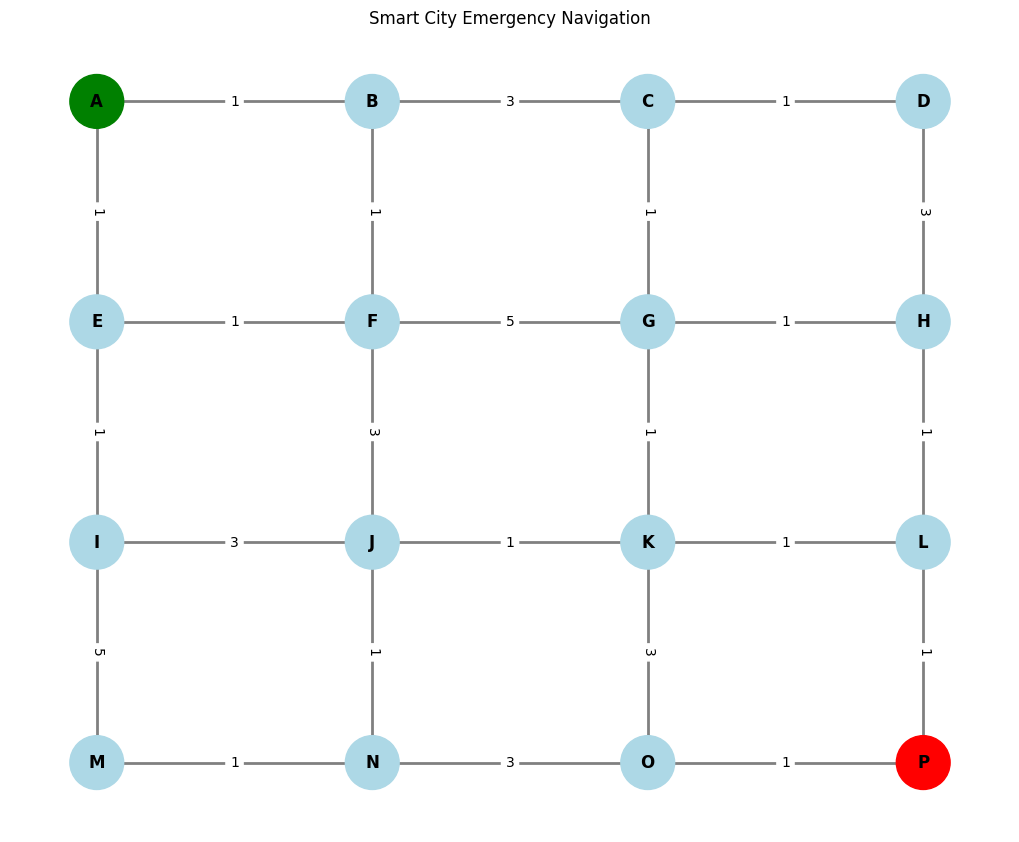

In [ ]:
# Define positions of all intersections

positions = {
    "A": (0, 3), "B": (1, 3), "C": (2, 3), "D": (3, 3),
    "E": (0, 2), "F": (1, 2), "G": (2, 2), "H": (3, 2),
    "I": (0, 1), "J": (1, 1), "K": (2, 1), "L": (3, 1),
    "M": (0, 0), "N": (1, 0), "O": (2, 0), "P": (3, 0)
}
plt.figure(figsize=(10, 8))

node_colors = []

for node in city.nodes():
    if node == "A":
        node_colors.append("green")
    elif node == "P":
        node_colors.append("red")
    else:
        node_colors.append("lightblue")

nx.draw(
    city,
    positions,
    with_labels=True,
    node_size=1500,
    node_color=node_colors,
    font_size=12,
    font_weight="bold",
    edge_color="gray",
    width=2
)

edge_labels = nx.get_edge_attributes(city, "weight")

nx.draw_networkx_edge_labels(
    city,
    positions,
    edge_labels=edge_labels,
    font_size=10
)

plt.title("Smart City Emergency Navigation")
plt.show()



In [ ]:

# Create a separate copy for testing
test_city = city.copy()

# Close road B-F
test_city.remove_edge("B", "F")

print("Road B-F has been closed.")

# Check if the road still exists
if test_city.has_edge("B", "F"):
    print("Road is available")
else:
    print("Road is blocked")


Road B-F has been closed.
Road is blocked


DFS Implementation

In [ ]:

def dfs_search(graph, start, goal):

    start_time = time.time()

    frontier = [start]

    visited = {start}
    came_from = {start: None}

    explored = set()

    while frontier:

        current_node = frontier.pop()

        if current_node == goal:

            path = []
            node = goal

            while node is not None:
                path.append(node)
                node = came_from[node]

            path.reverse()

            total_cost = 0

            for i in range(len(path) - 1):
                total_cost += graph[path[i]][path[i+1]]["weight"]

            execution_time = time.time() - start_time

            return path, total_cost, len(explored), execution_time

        explored.add(current_node)

        neighbors = list(graph.neighbors(current_node))

        for neighbor in reversed(neighbors):

            if neighbor not in visited:

                visited.add(neighbor)
                came_from[neighbor] = current_node
                frontier.append(neighbor)

    execution_time = time.time() - start_time

    return None, float("inf"), len(explored), execution_time


bfs implementation

In [ ]:

def bfs_search(graph, start, goal):

    start_time = time.time()

    frontier = deque([start])

    visited = {start}
    came_from = {start: None}

    explored = set()

    while frontier:

        current_node = frontier.popleft()

        if current_node == goal:

            path = []
            node = goal

            while node is not None:
                path.append(node)
                node = came_from[node]

            path.reverse()

            total_cost = 0

            for i in range(len(path) - 1):
                total_cost += graph[path[i]][path[i+1]]["weight"]

            execution_time = time.time() - start_time

            return path, total_cost, len(explored), execution_time

        explored.add(current_node)

        for neighbor in graph.neighbors(current_node):

            if neighbor not in visited:

                visited.add(neighbor)
                came_from[neighbor] = current_node
                frontier.append(neighbor)

    execution_time = time.time() - start_time

    return None, float("inf"), len(explored), execution_time


التشغيل

In [ ]:

bfs_path, bfs_cost, bfs_explored, bfs_time = bfs_search(city, "A", "P")

dfs_path, dfs_cost, dfs_explored, dfs_time = dfs_search(city, "A", "P")

print("BFS Results")
print("Path:", bfs_path)
print("Cost:", bfs_cost)
print("Explored Nodes:", bfs_explored)
print("Execution Time:", bfs_time)

print("\nDFS Results")
print("Path:", dfs_path)
print("Cost:", dfs_cost)
print("Explored Nodes:", dfs_explored)
print("Execution Time:", dfs_time)


BFS Results
Path: ['A', 'B', 'C', 'D', 'H', 'L', 'P']
Cost: 10
Explored Nodes: 15
Execution Time: 7.319450378417969e-05

DFS Results
Path: ['A', 'B', 'C', 'D', 'H', 'L', 'P']
Cost: 10
Explored Nodes: 12
Execution Time: 4.792213439941406e-05



 UCS Implementation

In [ ]:

def ucs_search(graph, start, goal):

    # Start measuring execution time
    start_time = time.time()

    # Priority Queue: (path_cost, current_node)
    frontier = []
    heapq.heappush(frontier, (0, start))

    # Store the best known cost to reach each node
    best_cost = {start: 0}

    # Store the previous node to reconstruct the path
    came_from = {}

    # Count expanded nodes
    explored = set()

    while frontier:

        # Get the node with the lowest path cost
        current_cost, current_node = heapq.heappop(frontier)

        # Ignore outdated entries
        if current_cost > best_cost[current_node]:
            continue

        # Stop when the goal is reached
        if current_node == goal:

            # Reconstruct the path
            path = []
            node = goal

            while node != start:
                path.append(node)
                node = came_from[node]

            path.append(start)
            path.reverse()

            execution_time = time.time() - start_time

            return path, current_cost, len(explored), execution_time

        # Mark current node as explored
        explored.add(current_node)

        # Explore neighboring nodes
        for neighbor, data in graph[current_node].items():

            road_cost = data["weight"]

            new_cost = current_cost + road_cost

            # Update if a cheaper path is found
            if new_cost < best_cost.get(neighbor, float("inf")):

                best_cost[neighbor] = new_cost
                came_from[neighbor] = current_node

                heapq.heappush(
                    frontier,
                    (new_cost, neighbor)
                )

    execution_time = time.time() - start_time

    return None, float("inf"), len(explored), execution_time


In [ ]:

# Run UCS on the original city
ucs_path, ucs_cost, ucs_explored, ucs_time = ucs_search(
    city,
    "A",
    "P"
)

print("===== UCS RESULTS =====")

print("Best Path:", ucs_path)
print("Total Path Cost:", ucs_cost)
print("Explored Nodes:", ucs_explored)
print("Execution Time:", ucs_time, "seconds")


===== UCS RESULTS =====
Best Path: ['A', 'B', 'C', 'G', 'H', 'L', 'P']
Total Path Cost: 8
Explored Nodes: 14
Execution Time: 0.000141143798828125 seconds


In [ ]:

# Run UCS after closing road B-F
blocked_path, blocked_cost, blocked_explored, blocked_time = ucs_search(
    test_city,
    "A",
    "P"
)

print("===== ROAD CLOSURE TEST =====")

print("Best Path:", blocked_path)
print("Total Cost:", blocked_cost)
print("Explored Nodes:", blocked_explored)
print("Execution Time:", blocked_time, "seconds")


===== ROAD CLOSURE TEST =====
Best Path: ['A', 'B', 'C', 'G', 'H', 'L', 'P']
Total Cost: 8
Explored Nodes: 14
Execution Time: 9.72747802734375e-05 seconds


Heuristic Function

In [ ]:
#مانهاتن

def heuristic(node, goal):

    x1, y1 = positions[node]
    x2, y2 = positions[goal]

    distance = abs(x1 - x2) + abs(y1 - y2)

    return distance


In [ ]:

def astar_search(graph, start, goal):

    start_time = time.time()

    # Priority Queue: (f_score, g_score, current_node)
    frontier = []

    heapq.heappush(
        frontier,
        (heuristic(start, goal), 0, start)
    )

    # Best actual cost from start to each node
    g_score = {start: 0}

    # Store the previous node
    came_from = {}

    # Store expanded nodes
    explored = set()

    while frontier:

        # Get the node with the lowest estimated total cost
        f_score, current_cost, current_node = heapq.heappop(frontier)

        # Ignore outdated entries
        if current_cost > g_score[current_node]:
            continue

        # Check if the goal is reached
        if current_node == goal:

            path = []
            node = goal

            while node != start:
                path.append(node)
                node = came_from[node]

            path.append(start)
            path.reverse()

            execution_time = time.time() - start_time

            return path, current_cost, len(explored), execution_time

        # Mark node as explored
        explored.add(current_node)

        # Check all neighboring intersections
        for neighbor, data in graph[current_node].items():

            road_cost = data["weight"]

            tentative_g = current_cost + road_cost

            # Update if a better path is found
            if tentative_g < g_score.get(neighbor, float("inf")):

                g_score[neighbor] = tentative_g
                came_from[neighbor] = current_node

                h_score = heuristic(neighbor, goal)

                f_score = tentative_g + h_score

                heapq.heappush(
                    frontier,
                    (f_score, tentative_g, neighbor)
                )

    execution_time = time.time() - start_time

    return None, float("inf"), len(explored), execution_time


In [ ]:

# Run A* on the original city
astar_path, astar_cost, astar_explored, astar_time = astar_search(
    city,
    "A",
    "P"
)

print("===== A* RESULTS =====")

print("Best Path:", astar_path)
print("Total Path Cost:", astar_cost)
print("Explored Nodes:", astar_explored)
print("Execution Time:", astar_time, "seconds")


===== A* RESULTS =====
Best Path: ['A', 'B', 'C', 'G', 'H', 'L', 'P']
Total Path Cost: 8
Explored Nodes: 13
Execution Time: 0.00011229515075683594 seconds


المقارنه بين الاتنين

In [ ]:

print("=" * 45)
print("       UCS vs A* COMPARISON")
print("=" * 45)

print(f"{'Metric':<22}{'UCS':<12}{'A*':<12}")
print("-" * 45)

print(f"{'Path Cost':<22}{ucs_cost:<12}{astar_cost:<12}")
print(f"{'Explored Nodes':<22}{ucs_explored:<12}{astar_explored:<12}")
print(f"{'Execution Time':<22}{ucs_time:<12.6f}{astar_time:<12.6f}")

print("-" * 45)

if ucs_cost == astar_cost:
    print("Both algorithms found an optimal path.")
else:
    print("The algorithms returned different path costs.")


       UCS vs A* COMPARISON
Metric                UCS         A*          
---------------------------------------------
Path Cost             8           8           
Explored Nodes        14          13          
Execution Time        0.000141    0.000112    
---------------------------------------------
Both algorithms found an optimal path.


المقارنه بين الاربعه

In [ ]:

algorithms = {
    "BFS": (bfs_path, bfs_cost, bfs_explored, bfs_time),
    "DFS": (dfs_path, dfs_cost, dfs_explored, dfs_time),
    "UCS": (ucs_path, ucs_cost, ucs_explored, ucs_time),
    "A*": (astar_path, astar_cost, astar_explored, astar_time)
}

print("SEARCH ALGORITHMS COMPARISON")
print("-" * 65)

for name, result in algorithms.items():

    path, cost, explored, execution_time = result

    print(f"\n{name}")
    print("Path:", path)
    print("Total Cost:", cost)
    print("Explored Nodes:", explored)
    print("Execution Time:", execution_time)


SEARCH ALGORITHMS COMPARISON
-----------------------------------------------------------------

BFS
Path: ['A', 'B', 'C', 'D', 'H', 'L', 'P']
Total Cost: 10
Explored Nodes: 15
Execution Time: 7.319450378417969e-05

DFS
Path: ['A', 'B', 'C', 'D', 'H', 'L', 'P']
Total Cost: 10
Explored Nodes: 12
Execution Time: 4.792213439941406e-05

UCS
Path: ['A', 'B', 'C', 'G', 'H', 'L', 'P']
Total Cost: 8
Explored Nodes: 14
Execution Time: 0.000141143798828125

A*
Path: ['A', 'B', 'C', 'G', 'H', 'L', 'P']
Total Cost: 8
Explored Nodes: 13
Execution Time: 0.00011229515075683594


هنرسم المسار بتاع افضل خورازميه بحث

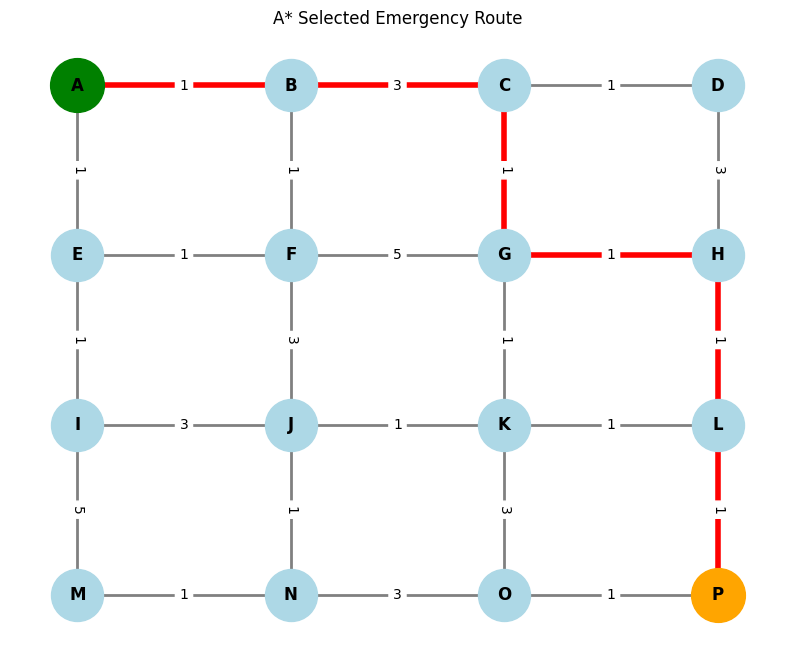

In [ ]:

# Create a list of edges in the selected path
path_edges = list(zip(astar_path, astar_path[1:]))

plt.figure(figsize=(10, 8))

# Draw all intersections
nx.draw_networkx_nodes(
    city,
    positions,
    node_color="lightblue",
    node_size=1400
)

# Draw all roads
nx.draw_networkx_edges(
    city,
    positions,
    edge_color="gray",
    width=2
)

# Highlight the selected route
nx.draw_networkx_edges(
    city,
    positions,
    edgelist=path_edges,
    edge_color="red",
    width=4
)

# Highlight start and goal
nx.draw_networkx_nodes(
    city,
    positions,
    nodelist=["A"],
    node_color="green",
    node_size=1500
)

nx.draw_networkx_nodes(
    city,
    positions,
    nodelist=["P"],
    node_color="orange",
    node_size=1500
)

nx.draw_networkx_labels(
    city,
    positions,
    font_weight="bold"
)

# Display road costs
edge_labels = nx.get_edge_attributes(city, "weight")

nx.draw_networkx_edge_labels(
    city,
    positions,
    edge_labels=edge_labels
)

plt.title("A* Selected Emergency Route")
plt.axis("off")
plt.show()


 Road Closure Scenario

 هنقفل الطريق C-G، وده طريق موجود في المسار الأساسي، ونشوف الخوارزميات هتختار إيه بدلًا منه.

In [ ]:

# Create a copy of the original city
closure_city = city.copy()

# Close road C-G
closure_city.remove_edge("C", "G")

# Run UCS
ucs_closure = ucs_search(closure_city, "A", "P")

# Run A*
astar_closure = astar_search(closure_city, "A", "P")

print("===== ROAD CLOSURE SCENARIO =====")

print("\nUCS:")
print("Path:", ucs_closure[0])
print("Cost:", ucs_closure[1])
print("Explored:", ucs_closure[2])

print("\nA*:")
print("Path:", astar_closure[0])
print("Cost:", astar_closure[1])
print("Explored:", astar_closure[2])


===== ROAD CLOSURE SCENARIO =====

UCS:
Path: ['A', 'B', 'F', 'J', 'K', 'L', 'P']
Cost: 8
Explored: 14

A*:
Path: ['A', 'B', 'F', 'J', 'K', 'L', 'P']
Cost: 8
Explored: 11


تخيل إن الطريق B-C حصل فيه ازدحام شديد، وتكلفته زادت من 3 إلى 8.

In [ ]:

# Create a copy of the original city
traffic_city = city.copy()

# Increase traffic cost on road B-C
traffic_city["B"]["C"]["weight"] = 8

# Run UCS
ucs_traffic = ucs_search(traffic_city, "A", "P")

# Run A*
astar_traffic = astar_search(traffic_city, "A", "P")

print("===== TRAFFIC UPDATE SCENARIO =====")

print("\nUCS:")
print("Path:", ucs_traffic[0])
print("Cost:", ucs_traffic[1])

print("\nA*:")
print("Path:", astar_traffic[0])
print("Cost:", astar_traffic[1])


===== TRAFFIC UPDATE SCENARIO =====

UCS:
Path: ['A', 'B', 'F', 'J', 'K', 'L', 'P']
Cost: 8

A*:
Path: ['A', 'B', 'F', 'J', 'K', 'L', 'P']
Cost: 8


In [ ]:

scenarios = {
    "Normal City": (ucs_search(city, "A", "P"),
                    astar_search(city, "A", "P")),

    "Road Closure": (ucs_closure, astar_closure),

    "Traffic Changes": (ucs_traffic, astar_traffic)
}

print("=" * 65)
print("             FINAL PROJECT RESULTS")
print("=" * 65)

for scenario, results in scenarios.items():

    ucs_result, astar_result = results

    print(f"\nScenario: {scenario}")
    print("-" * 45)

    print("UCS Cost:", ucs_result[1])
    print("A* Cost:", astar_result[1])

    print("UCS Explored:", ucs_result[2])
    print("A* Explored:", astar_result[2])

    print("Same Optimal Cost:",
          ucs_result[1] == astar_result[1])


             FINAL PROJECT RESULTS

Scenario: Normal City
---------------------------------------------
UCS Cost: 8
A* Cost: 8
UCS Explored: 14
A* Explored: 13
Same Optimal Cost: True

Scenario: Road Closure
---------------------------------------------
UCS Cost: 8
A* Cost: 8
UCS Explored: 14
A* Explored: 11
Same Optimal Cost: True

Scenario: Traffic Changes
---------------------------------------------
UCS Cost: 8
A* Cost: 8
UCS Explored: 13
A* Explored: 9
Same Optimal Cost: True
